This is a simple notebook, built over a few days to explore the processing of calcium imaging data from a head-mounted miniscope (something that's new to me). I used a public dataset (DANDI 002047, dorsal CA1, GCaMP6s, UCLA Miniscope, mouse F06, memory-test session).

It covers the development of a simple activation detector based on classical image processing methods, to better understand the nature of the data I would have to work with, as well as some of the problems the standard tools of the field solve. 85% of the zones it detects lie inside a CaImAn cell (vs 26% chance), and the median trace correlation is 0.93 on the first chunk and 0.91 on the whole session.

*Reproducibility:* the outputs are saved, so the notebook reads without running it. Run top to bottom (expect a few minutes; the first run downloads ~1 GB from DANDI and writes ~6 GB more, all inside this folder, in `data/` and `out/`, delete them to clean up), it gives the same numbers and figures (fixed random seeds; the whole-session results are loaded from `out/session` if `streaming.py` has already produced them). Movies are written to `out/` rather than embedded; each one is shown here as a single still frame.

**Jump to:**
- [Binary activation map in time (rise detector)](#rise-movie)
- [My detector vs chance (table)](#chance-table)
- [Traces, first chunk (33 s)](#traces-chunk)
- [Traces, whole session (5 min)](#traces-session)

The first half of this notebook explains my reasoning and the different processing steps my minimal detector takes in terms of preprocessing, to isolate transients, remove the background, model the noise and finally detect activation events. The second part evaluates it against a CNMF-E run with the authors' parameters, and with their full run, curation included.

_LLM use disclosure: The detection chain is mine. The CaImAn setup, zone grouping, evaluation code and streaming were written with a coding assistant from my specifications._

In [1]:
import os, logging
# CaImAn writes its temporary memmaps (~2 GB) to ~/caiman_data/temp by default; keep them in this folder instead
os.makedirs("out/caiman_temp", exist_ok=True)
os.environ["CAIMAN_TEMP"] = os.path.abspath("out/caiman_temp")
# Two harmless messages silenced here:
# - macOS prints 'Class ... is implemented in both' at import because opencv and PyAV each bundle libavdevice.
#   It comes from the system, not Python, so stderr is redirected at the file-descriptor level during the imports.
# - CaImAn's own warnings (negative movie mean, deprecated parameter style, a least-squares fallback): logger set to ERROR.
_stderr = os.dup(2)
os.dup2(os.open(os.devnull, os.O_WRONLY), 2)
try:
    from caiman.motion_correction import MotionCorrect
    from caiman.source_extraction.cnmf import cnmf, params
    from caiman.summary_images import correlation_pnr

    import imageio.v3 as iio
    from IPython.display import Video

    import caiman as cm
    import numpy as np
    import cv2
    import av
finally:
    os.dup2(_stderr, 2); os.close(_stderr)
logging.getLogger('caiman').setLevel(logging.ERROR)

from pathlib import Path
from scipy import ndimage
from matplotlib import pyplot as plt

Path("out").mkdir(exist_ok=True)

def show_movie(name, frames, lo, hi, still=None, quality=6):
    """Write a contrast-stretched movie to out/<name>.mp4 (not embedded in the notebook: Jupyter serves it from disk)
    and show one still frame inline, so the notebook reads without the video."""
    u8 = (np.clip((frames - lo) / (hi - lo), 0, 1) * 255).astype(np.uint8)
    path = f"out/{name}.mp4"
    iio.imwrite(path, u8, extension=".mp4", fps=30, codec="libx264", quality=quality, macro_block_size=1)
    t = len(frames) // 2 if still is None else still
    fig, ax = plt.subplots(figsize=(4 * frames.shape[2] / frames.shape[1], 4))
    ax.imshow(u8[t], cmap="Greys_r", vmin=0, vmax=255); ax.set_axis_off()
    ax.set_title(f"{name}, frame {t} (movie: {path})", fontsize=8)
    plt.show()
    del u8
    return Video(path, width=min(600, 2 * frames.shape[2]))


In [2]:
# Data: session S3 of mouse F06 from DANDI 002047 (raw movie + the authors' NWB, ~1 GB), downloaded on the first run
files = sorted(Path('data/sub-F06/sub-F06_ses-CPFE-F06-S3_ophys').glob('*.avi'))
if len(files) < 9:
    import download
    download.download()
    files = sorted(Path('data/sub-F06/sub-F06_ses-CPFE-F06-S3_ophys').glob('*.avi'))
fname = files[0]   # first of the 9 files of the session: 1000 frames, ~33 s

In [3]:
m = cm.load(fname)
ms = m.resize(0.5, 0.5, 1)
del m              # full-resolution movie no longer needed (1.4 GB)

# Field of view: the GRIN lens projects a circular image; outside the inscribed circle of the frame there is no signal.
# Applied after the spatial high-pass (so the blur never sees an artificial edge) and to CaImAn's components after the fit.
yy, xx = np.mgrid[:ms.shape[1], :ms.shape[2]]
fov = np.hypot(yy - (ms.shape[1] - 1) / 2, xx - (ms.shape[2] - 1) / 2) <= ms.shape[1] / 2   # r <= 150 px at 300x300

## Stabilisation

The miniscope is fixed to the head, but the brain still moves slightly under the lens. Before anything else I register every frame to a common template with CaImAn's rigid motion correction (NoRMCorre), on the full-resolution movie, then downsample ×2 like the raw movie. The first 4 frames are camera start-up frames (black or partial) and are dropped from here on.

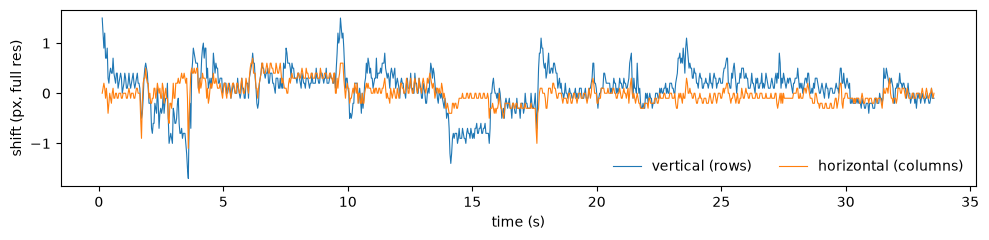

shift std: 0.40 / 0.21 px, range 3.2 / 1.8 px (vertical / horizontal, full resolution; 1 px = 1.6 um)


In [4]:
mc = MotionCorrect([str(fname)], max_shifts=(35, 35), gSig_filt=(8, 8),
                   pw_rigid=False, border_nan='copy')
mc.motion_correct(save_movie=True)
mms = cm.load(mc.mmap_file[0]).resize(0.5, 0.5, 1)    # stabilised movie, 300x300

shifts = np.array(mc.shifts_rig)[4:]                   # rigid shift of each frame, full-resolution px (start-up frames dropped)
t = np.arange(4, 4 + len(shifts)) / 29.78
fig, ax = plt.subplots(figsize=(10, 2.5))
ax.plot(t, shifts[:, 0], lw=.8, label="vertical (rows)")
ax.plot(t, shifts[:, 1], lw=.8, label="horizontal (columns)")
ax.set_xlabel("time (s)"); ax.set_ylabel("shift (px, full res)"); ax.legend(frameon=False, ncol=2)
fig.tight_layout(); plt.show()
print(f"shift std: {shifts[:, 0].std():.2f} / {shifts[:, 1].std():.2f} px, range {np.ptp(shifts[:, 0]):.1f} / {np.ptp(shifts[:, 1]):.1f} px "
      f"(vertical / horizontal, full resolution; 1 px = 1.6 um)")

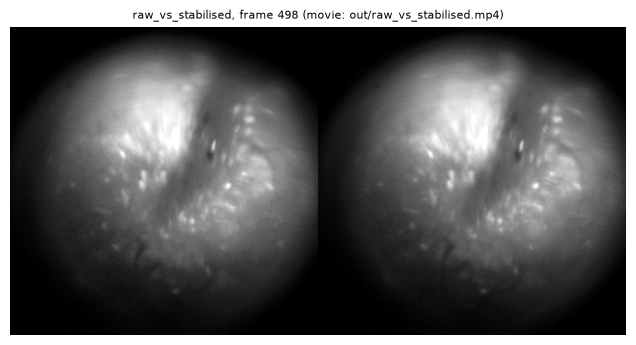

In [5]:
# Raw (left) and stabilised (right), same contrast stretch
both = np.concatenate([ms[4:], mms[4:]], axis=2)
lo, hi = np.percentile(both, [1, 99.5])
v = show_movie("raw_vs_stabilised", both, lo, hi)
del both, ms    # only the stabilised movie is used from here on
v

With these images, we're supposed to see neurons firing, but on the raw data above, this isn't visible at all. It's more like a mess of haze, and hard to discern any signature, plus a strong constant background. Let's try to fix this, by first removing the low spatial frequency information.

In [6]:
low = np.array([cv2.GaussianBlur(frame, (45, 45), 4.5) for frame in mms[4:]])
high = mms[4:] - low
high[:, ~fov] = 0          # outside the lens circle: no information

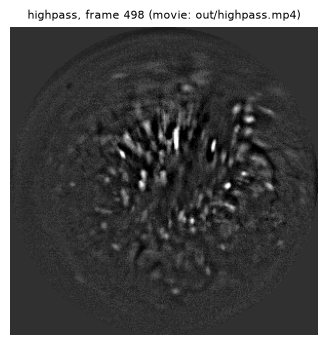

In [7]:
lo, hi = np.percentile(high, [1, 99.9])
show_movie("highpass", high, lo, hi)

Low spatial frequency data is removed by subtracting it from the raw data, and the image looks more like a "brain" now, I think I can start to see neurons firing. However, there's a lot of shot noise there. Since this is a quick demo and I don't care about having the best possible extraction, I'll address it using temporal smoothing.

The dark haloes are an artefact of the high-pass filter.

Now to remove the shot noise. I do this with a simple low pass filter in the time domain.

In [8]:
high_slow = ndimage.uniform_filter1d(high, 5, axis=0)

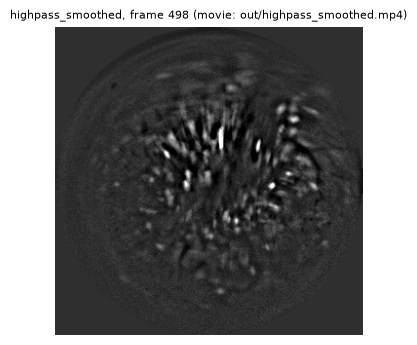

In [9]:
lo, hi = np.percentile(high_slow, [1, 99.9])
show_movie("highpass_smoothed", high_slow, lo, hi)

And here it is, the movie from above, simply averaged in the time axis over five frames, or 167ms at 30fps. Averaging is a bit of a naive way of dealing with shot noise, and using say time correlations of the pixels over time would work better, but then again I just want to see neurons firing now.

There are also a few other things we can start to see: it looks like we have much better resolution and SNR on axis, and that the edges of the field of view are quite distorted, with a "fisheye" effect of some sort. I don't know the exact optical setup, but I'd guess it's a function of the lens that imposes a heavy vignetting, and I would expect a large amount of field curvature as well.

In [10]:
high_slow_flat = high_slow / np.maximum(low.mean(axis=0)[np.newaxis,:,:], 1)

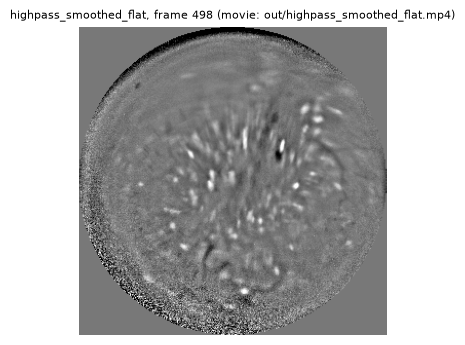

In [11]:
lo, hi = np.percentile(high_slow_flat, [1, 99.9])
show_movie("highpass_smoothed_flat", high_slow_flat, lo, hi)

In [12]:
del high_slow_flat
base = ndimage.grey_opening(high_slow, size=(299, 1, 1))   # 299 frames ≈ 10 s, along time only
act = high_slow - base
del low, high, high_slow, base

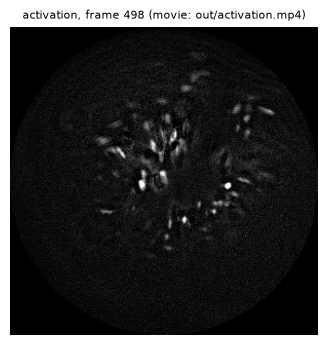

In [13]:
lo, hi = np.percentile(act, [1, 99.9])
show_movie("activation", act, lo, hi)

This is the result of the subtraction from the image of a time-wise morphological opening over a ten second window, acting as a background estimate. It takes the windowed minimum over 299 frames, then applies a local time-wise maximum over the same window. This kills some of the systematic drift, and improves the contrast with transients.

Now let's look at the processed activation movie again. The dynamic range is pretty compressed, so I'll use a square root to stretch the display.

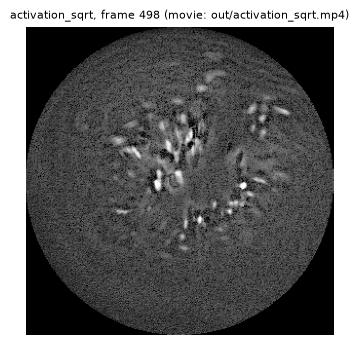

In [14]:
lo, hi = np.percentile(act**.5, [1, 99.9])
show_movie("activation_sqrt", act**.5, lo, hi)

Now we can see activations clearly, as well as some other perturbations, such as blood pulsating in vessels. We could run a simple, max-based extraction:

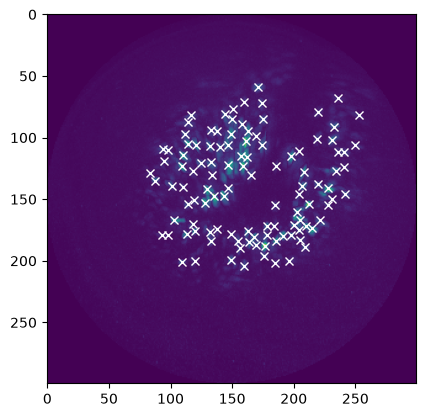

In [15]:
peak = act.max(axis=0)
thr = np.percentile(peak[fov], 95)     # threshold from inside the lens circle only
pk = np.argwhere((peak == ndimage.maximum_filter(peak, size=7)) & (peak > thr))

plt.imshow(peak)
plt.plot(pk[:,1],pk[:,0],'wx');

That does work, but looking at the movie again, I'd like to be able to do a few things:

- Firstly, shot noise is visible in the processed movie, and I would like to be able to evaluate the noise level for each pixel. That will allow me to set a threshold based on this estimate, and only detect when a pixel gets hotter than a peak.
- Activation events follow a specific sequence: a blob of pixels brightens with a fast ramp up, and then decays slowly. I would like a criterion that catches this specific sequence, with say a set number of contiguous pixels brightening by a set amount over a set time, then decaying at a specific rate, and to flag this as an activation.
- Following from the previous point, I also would like to extract a time signal: detect when, and not only where neurons activate.

For the noise, let's first look at the brightest maximum used to find the peaks and see if we can isolate the dead times, between activations:

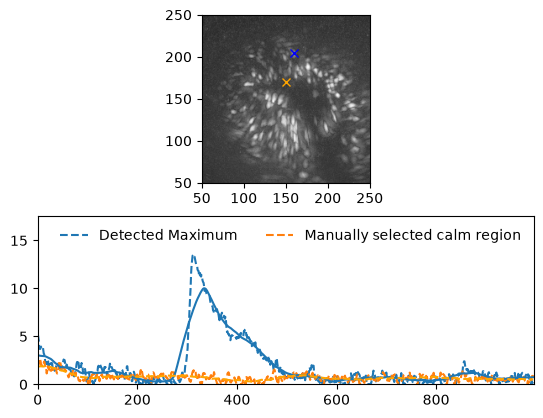

In [16]:
max_pos = pk[-1]
calm_pos = [170,150]
act_ref = ndimage.uniform_filter1d(act, 61, axis=0)

fig, ax = plt.subplots((2))
ax[0].imshow(peak**.5,cmap='Greys_r')
ax[0].set_xlim(50,250)
ax[0].set_ylim(50,250)
ax[0].plot(max_pos[1],max_pos[0],'xb')
ax[0].plot(calm_pos[1],calm_pos[0],marker='x',color='orange')
ax[1].plot(act[:,max_pos[0],max_pos[1]],label='Detected Maximum',linestyle='--')
ax[1].plot(act[:,calm_pos[0],calm_pos[1]],label='Manually selected calm region',linestyle='--')
ax[1].legend(frameon=False,ncol=2)
ax[1].set_xlim(0,len(act))
ax[1].set_ylim(0,act[:,max_pos[0],max_pos[1]].max()*1.3)
ax[1].plot(act_ref[:,max_pos[0],max_pos[1]],color='tab:blue')
ax[1].plot(act_ref[:,calm_pos[0],calm_pos[1]],color='orange',linestyle='--');

The solid line represents the two second average of each pixel, and I'll estimate the noise from the lowest 20% of this value, thus:

In [17]:
calm = act_ref <= np.percentile(act_ref, 20, axis=0)
resid = np.where(calm, act - act_ref, np.nan) 
noise = np.nanstd(resid, axis=0) 
del resid

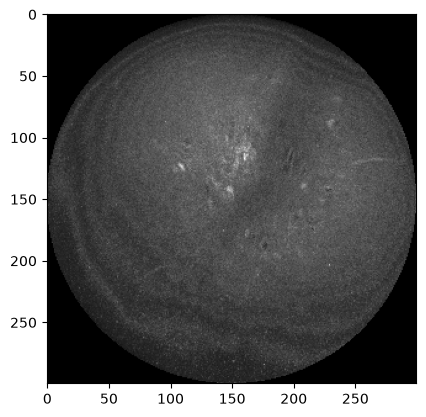

In [18]:
plt.imshow(noise,cmap="Greys_r");

<a id="rise-movie"></a>
Now, let's use this estimated noise and a bit of morphology again to find activations. The rule is simple: a frame-to-frame rise of more than 0.7 times the pixel's noise level, sustained for 5 frames in a row, over a patch of at least 2×2 pixels. This is a simple rule, meant to detect activations over time.

In [19]:
act_diff = np.diff(act,axis=0)
rising = act_diff > .7 * noise
rise = ndimage.binary_erosion(rising, structure=np.ones((5, 2, 2), bool))
del act_diff, rising, act_ref

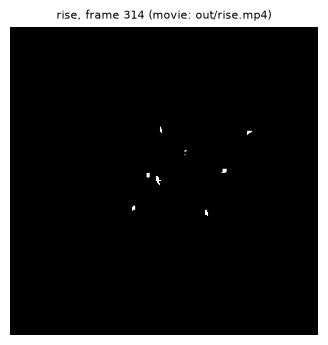

In [20]:
show_movie("rise", rise.astype(np.float32), 0, 1, still=int(rise.sum((1, 2)).argmax()))

This shows activations as they happen, with a ~3-frame lag (due to time domain erosion). 

In [21]:
onsets = (np.diff((rise > 0).astype(np.int8), axis=0) == 1).sum(0)
sm = ndimage.gaussian_filter(onsets.astype(np.float32), 1.5)
pk_rise = np.argwhere((sm == ndimage.maximum_filter(sm, size=7)) & (onsets > 0))

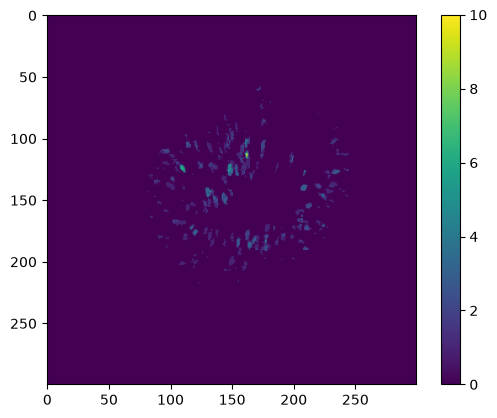

In [22]:
plt.imshow(onsets); plt.colorbar();

## Zones: grouping events into cell-like regions

Each 3-D connected blob of `rise` is an event. Events whose footprints overlap (intersection over union > 0.5) are grouped into a zone; zones seen at least twice are kept, which removes most of the one-off noise detections. A zone's trace is the mean of `act` over its pixels.

34 zones seen at least twice, median area 18 px


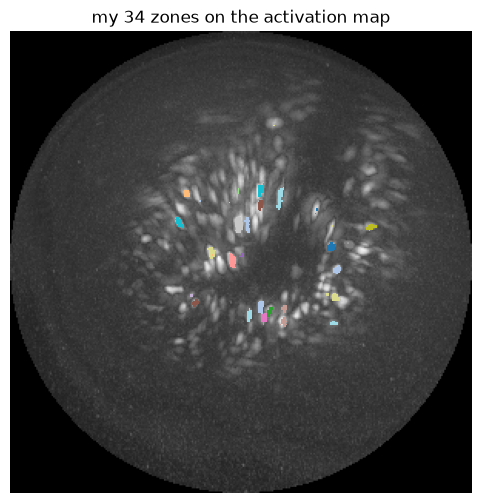

In [23]:
# Zones from my rise events (events whose footprints overlap) and their traces from act.
import scipy.sparse as sp
from scipy.sparse.csgraph import connected_components

def label_sparse(rise):
    """Same as ndimage.label(rise) (face connectivity, same label order), but only touches the active voxels."""
    T, H, W = rise.shape
    t, y, x = np.nonzero(rise)                      # C order, so the keys below are sorted
    key = (t * H + y) * W + x
    n = len(key)
    rows, cols = [], []
    for off, ok in ((1, x < W - 1), (W, y < H - 1), (H * W, t < T - 1)):   # +x, +y, +t neighbours
        j = np.searchsorted(key, key + off)
        hit = ok & (j < n)
        hit[hit] = key[j[hit]] == key[hit] + off
        rows.append(np.flatnonzero(hit)); cols.append(j[hit])
    rows, cols = np.concatenate(rows), np.concatenate(cols)
    G = sp.csr_matrix((np.ones(len(rows), bool), (rows, cols)), shape=(n, n))
    n_ev, lab = connected_components(G, directed=False)   # numbered by first voxel in raster order, like ndimage.label
    return t, y, x, lab, n_ev

def zone_traces(act, zmap, ids):
    """Mean of act over each zone's pixels: (T, zones)."""
    px = np.flatnonzero(zmap)
    z = np.searchsorted(ids, zmap.ravel()[px])                  # row of each pixel's zone
    Zm = sp.csr_matrix((1 / np.bincount(z)[z], (z, px)), shape=(len(ids), zmap.size))
    return act.reshape(len(act), -1) @ Zm.T

def event_zones(rise, iou=0.5, min_events=2):
    """Group 3-D rise events into zones: events whose footprints overlap (IoU > iou) belong to the same zone."""
    T, H, W = rise.shape
    t, y, x, lab, n_ev = label_sparse(rise)
    t_first = t[np.unique(lab, return_index=True)[1]]           # first frame of each event (voxels are in time order)
    F = sp.csr_matrix((np.ones(len(lab)), (lab, y * W + x)), shape=(n_ev, H * W))
    F.data[:] = 1                                               # footprint of each event
    area = F.getnnz(1)
    inter = (F @ F.T).tocoo()                                   # pixels shared by each pair of events
    ratio = inter.data / (area[inter.row] + area[inter.col] - inter.data)
    G = sp.csr_matrix((ratio, (inter.row, inter.col)), shape=(n_ev, n_ev)) > iou
    n_z, ev_zone = connected_components(G, directed=False)
    n_events = np.bincount(ev_zone)
    counts = sp.csr_matrix((np.ones(n_ev), (ev_zone, np.arange(n_ev)))) @ F   # (zone, pixel): events of the zone covering it
    best = counts.argmax(0).A1
    zmap = np.where((counts.getnnz(0) > 0) & (n_events[best] >= min_events), best + 1, 0).reshape(H, W)
    return zmap, n_events, ev_zone, t_first

zmap, n_events, ev_zone, t_first = event_zones(rise)
ids = np.unique(zmap[zmap > 0])                              # kept zones (labels in zmap are zone index + 1)
print(f"{len(ids)} zones seen at least twice, median area {np.median(np.bincount(zmap.ravel())[ids]):.0f} px")

# Zone traces: mean of act over each zone's pixels (aperture photometry with my own apertures)
T = act.shape[0]
traces = zone_traces(act, zmap, ids)                         # (T, zones)

# Zone map on the activation map, one colour per zone
fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(peak ** .5, cmap='Greys_r')
lut = np.random.default_rng(0).integers(0, 20, zmap.max() + 1)          # shuffled colours, so neighbours differ
ax.imshow(np.ma.masked_where(zmap == 0, lut[zmap]), cmap='tab20', vmin=0, vmax=19, interpolation='nearest')
ax.set_axis_off(); ax.set_title(f"my {len(ids)} zones on the activation map");

What looks like activations appear, but some noise makes it through.

## CaImAn CNMF-E on the motion-corrected chunk

Same chunk, ×2 downsampled, start-up frames dropped. Parameters are the authors' (stored in the NWB, `processing/ophys/processing_parameters`). Pixel-valued ones are halved for the downsampling: gSig 4 → 2, gSiz 17 → 9, patch half-size rf 40 → 20, patch overlap stride 25 → 12. Ratios are kept (ring_size_factor 1.5). The authors computed the background at 2× spatial downsampling (ssub_B 2), so on data already downsampled ×2 the equivalent is ssub_B 1. I will not claim to understand what all the parameters mean, I simply lifted them from the files to try and reproduce their run.

In [24]:
# CNMF-E wants a C-order memmap; this also downsamples x2 and drops the 4 start-up frames
fname_new = cm.save_memmap([mc.mmap_file[0]], base_name='cnmfe_', order='C',
                           resize_fact=(0.5, 0.5, 1), remove_init=4)
Yr, dims, T = cm.load_memmap(fname_new)
images = np.reshape(Yr.T, [T] + list(dims), order='F')

In [25]:
opts = params.CNMFParams(params_dict={
    'fr': 29.78, 'decay_time': 1.0, 'p': 1,            # frame rate, GCaMP6s decay (s), AR(1) deconvolution
    'method_init': 'corr_pnr', 'K': None,              # CNMF-E seeding from correlation x PNR, no fixed cell count
    'gSig': (2, 2), 'gSiz': (9, 9), 'center_psf': True,  # cell radius and patch size (px at 300x300)
    'min_corr': 0.9, 'min_pnr': 10,                    # seed thresholds (authors' values)
    'ring_size_factor': 1.5, 'ssub_B': 1,              # ring background: radius = 1.5 x gSiz (authors')
    'nb': 0, 'nb_patch': 0, 'low_rank_background': None,
    'rf': 20, 'stride': 12, 'only_init': True,         # patches: half-size 20 px, overlap 12 px (authors' 40, 25 halved)
    'ssub': 1, 'tsub': 1, 'merge_thr': 0.8,
    'normalize_init': False, 'update_background_components': True,
    'method_deconvolution': 'oasis', 'del_duplicates': True, 'border_pix': 0,
})

In [26]:
cnm = cnmf.CNMF(n_processes=1, params=opts, dview=None)
import warnings   # silence a harmless scipy warning CaImAn triggers ~60 times
warnings.filterwarnings('ignore', message='divide by zero encountered in remainder')
np.random.seed(0)        # CaImAn draws a few random numbers internally; fixed for reproducibility
cnm.fit(images)          # ~100 s on this chunk (patches run one after another without a cluster)
# Same field-of-view mask for CaImAn: keep only components whose centre of mass lies inside the lens circle
com_px = np.clip(np.round(cm.base.rois.com(cnm.estimates.A, *dims)).astype(int), 0, np.array(dims) - 1)
inside = fov[com_px[:, 0], com_px[:, 1]]
print(f"components inside the lens circle: {inside.sum()}/{len(inside)}")
cnm.estimates.select_components(idx_components=np.flatnonzero(inside))
cnm.estimates.A.shape, cnm.estimates.C.shape   # (pixels, components), (components, frames)

components inside the lens circle: 135/140


((90000, 135), (135, 996))

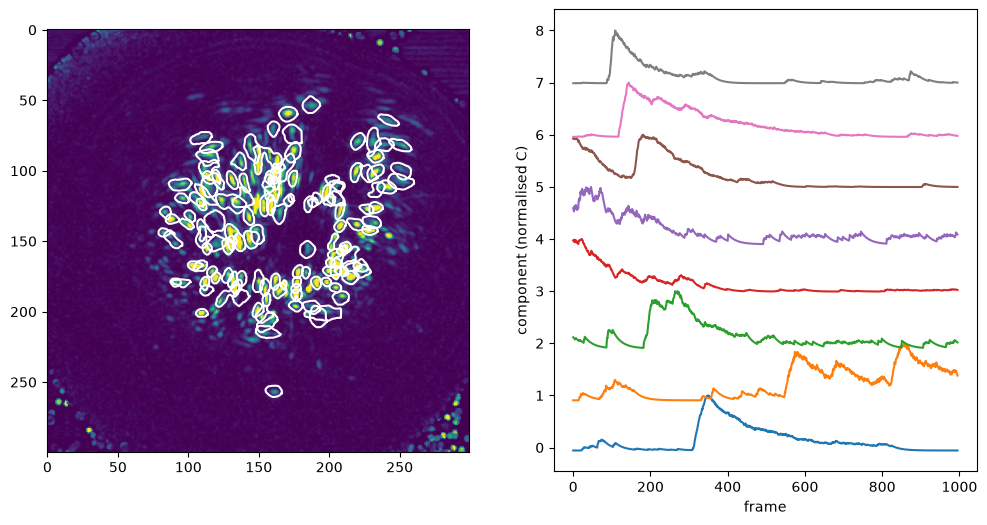

In [27]:
from caiman.utils.visualization import plot_contours
cn, pnr = correlation_pnr(images, gSig=2, swap_dim=False)
C = cnm.estimates.C[:8]
fig, ax = plt.subplots(1, 2, figsize=(12, 6))
plt.sca(ax[0]); plot_contours(cnm.estimates.A, cn * pnr, display_numbers=False)
ax[1].plot(C.T / C.max(axis=1) + np.arange(len(C)))
ax[1].set_xlabel('frame'); ax[1].set_ylabel('component (normalised C)');

Now the interesting question: how well did my own pipeline, zones and all, actually locate the cells? Let's plot CaImAn's contours in black, and my zones in colour.

In [28]:
from caiman.utils.visualization import get_contours
conts = get_contours(cnm.estimates.A, dims, thr=0.2, thr_method='max')

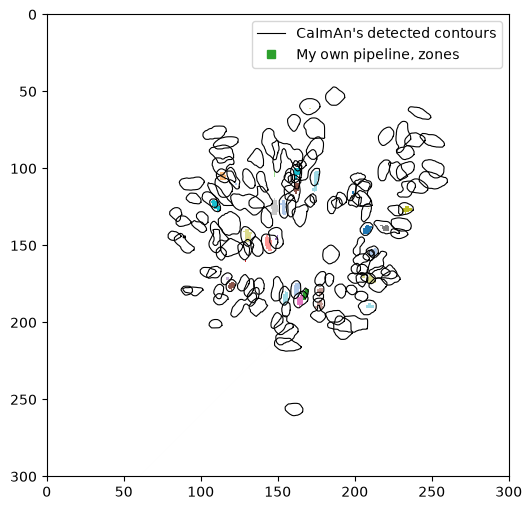

In [29]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(np.ma.masked_where(zmap == 0, lut[zmap]), cmap='tab20', vmin=0, vmax=19, interpolation='nearest')
for i, c in enumerate(conts):
    ax.plot(*c['coordinates'].T, 'k', lw=0.8, label="CaImAn's detected contours" if i == 0 else None)
ax.plot([], [], 's', color='tab:green', label="My own pipeline, zones")      # legend entry for the zone patches
ax.set_xlim(0, dims[1]); ax.set_ylim(dims[0], 0); ax.set_aspect('equal')
ax.legend();

# Evaluating precision and recall

The plot above shows a pretty good agreement, with the zones produced by my own minimal detector sitting mostly within a CaImAn contour. To quantify it, let's define a few criteria for the comparison: 

- Number of detected zones with at least 80% of their pixels inside a single CaImAn contour (true positives)
- Number of detected zones with more than 20% of their pixels outside any single contour, i.e. straddling two cells or partly outside every cell (false positives)
- Number of CaImAn contours with none of my zones inside them (misses)

In [30]:
# My zones vs CaImAn's components, in space.
# A zone is found if >= 80% of its pixels lie inside a single CaImAn cell (footprint mask A > 0.2 max);
# a zone straddling two cells, or partly outside every cell, is a miss.
# Chance: each zone's shape rotated by a random angle and moved to random places, drawn more often where CaImAn cells are dense
# (stacked CaImAn masks blurred by a Gaussian of one cell diameter), 200 times.
import fullsession
A = cnm.estimates.A.toarray(); K = A.shape[1]
masks = (A > 0.2 * A.max(0)).reshape(*dims, K, order='F').reshape(-1, K).astype(np.float32)   # (pixels, cells)
inside = fullsession.containment(zmap, ids, masks, fov)
n, f = inside['n_zones'], inside['n_found']          # my zones, and how many sit inside a single CaImAn cell
K, k = inside['n_ref'], inside['n_cells_found']      # CaImAn cells, and how many contain one of my zones
print(f"my zones >= 80% inside a single CaImAn cell: {f}/{n} ({f / n:.0%})")
print(f"my zones straddling two cells or outside:    {n - f}/{n} ({(n - f) / n:.0%})")
print(f"CaImAn cells with none of my zones inside:   {K - k}/{K} ({(K - k) / K:.0%})")

my zones >= 80% inside a single CaImAn cell: 29/34 (85%)
my zones straddling two cells or outside:    5/34 (15%)
CaImAn cells with none of my zones inside:   108/135 (80%)


This matches the plot: my detector has good precision, but poor recall: its simplicity and the fact it only looks for part of the exploitable information means it misses most of what CaImAn detects.

# Comparison with chance

Detections can be compared with chance inside the whole image circle, but I think it oversells, because cells are clustered in a minority of the image area, and detecting roughly where activations happen is quite trivial. So instead, I use a stricter comparator: zones are rotated at random, and then placed in the image area according to a probability density that follows CaImAn's detected contours. Then, the comparison from above is run again on 200 samples with my scrambled zones to get the chance levels. The placement probability is shown below:

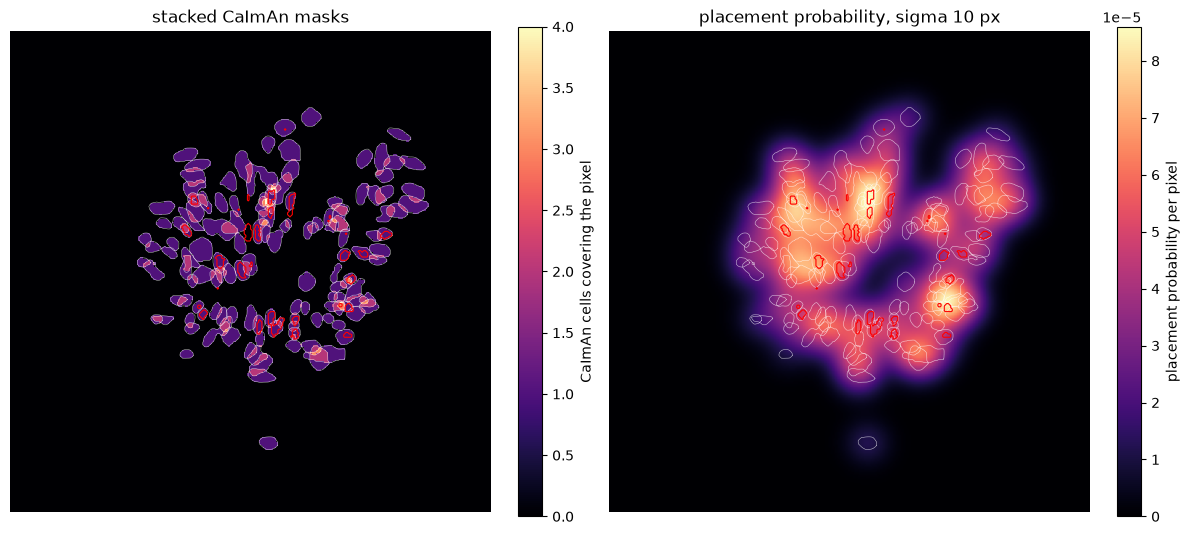

In [31]:
# The chance level's placement map: where a randomly moved zone lands, with CaImAn's contours (white) and my zones (red)
fig, ax = plt.subplots(1, 2, figsize=(12, 6))
im0 = ax[0].imshow(masks.sum(1).reshape(dims), cmap='magma', interpolation='nearest')
fig.colorbar(im0, ax=ax[0], fraction=0.046, label="CaImAn cells covering the pixel")   # a colour bar on each panel keeps them the same size
ax[0].set_title("stacked CaImAn masks")
im1 = ax[1].imshow(inside['density'], cmap='magma')
fig.colorbar(im1, ax=ax[1], fraction=0.046, label="placement probability per pixel")
ax[1].set_title(f"placement probability, sigma {inside['sigma']:.0f} px")
for a in ax:
    for c in conts:
        a.plot(*c['coordinates'].T, color='w', lw=0.4, alpha=0.7)
    a.contour(zmap > 0, [0.5], colors='red', linewidths=0.8)
    a.set_axis_off()
fig.tight_layout()

 <a id="chance-table"></a>
and the chance performance:

In [32]:
# My detector vs chance (zones rotated and moved at random, 200 times, with the placement map above)
import pandas as pd
pc, rc = inside['prec_chance'], inside['rec_chance']   # chance: share of zones inside one cell, share of cells with a zone
pd.DataFrame({
    "my pipeline": [f"{f}/{n} ({f / n:.0%})", f"{n - f}/{n} ({(n - f) / n:.0%})",
                    f"{k}/{K} ({k / K:.0%})", f"{K - k}/{K} ({(K - k) / K:.0%})"],
    "chance":      [f"{pc * n:.1f}/{n} ({pc:.0%})", f"{(1 - pc) * n:.1f}/{n} ({1 - pc:.0%})",
                    f"{rc * K:.1f}/{K} ({rc:.0%})", f"{(1 - rc) * K:.1f}/{K} ({1 - rc:.0%})"],
}, index=["zones >= 80% inside a single CaImAn cell", "zones straddling two cells or outside",
          "CaImAn cells with one of my zones inside", "CaImAn cells with none of my zones"])

,my pipeline,chance
zones >= 80% inside a single CaImAn cell,29/34 (85%),9.0/34 (26%)
zones straddling two cells or outside,5/34 (15%),25.0/34 (74%)
CaImAn cells with one of my zones inside,27/135 (20%),8.6/135 (6%)
CaImAn cells with none of my zones,108/135 (80%),126.4/135 (94%)


My detector is significantly better than chance, even with this stricter rule. I also ran the test with 10,000 random draws: the best draw for each line of the table above was, respectively, 56%, 44%, 13% and 87%, so no draw did as well as my detector (p < 10⁻⁴). The script is `chance_test.py`; `python chance_test.py chunk` reproduces these numbers (it reruns motion correction and CaImAn on this chunk, ~2.5 min).

In [33]:
# Activation movie (streamed frame by frame, low RAM).
# Left: my activation movie. Right: CaImAn's A·C(t). My rise detections in red on both.
from pathlib import Path

def activation_movie(path, act, rise, A, C, fps=30, trail=0.85):
    T = len(act)
    lo, hi = np.percentile(act[::10] ** .5, [1, 99.9])
    A = A.multiply(1 / A.max(0).toarray()).tocsc()                 # each footprint scaled to peak 1
    C = C / C.max(1, keepdims=True)                                # each trace scaled to peak 1
    red = np.zeros(act.shape[1:], np.float32)
    with iio.imopen(path, "w", plugin="pyav") as f:
        f.init_video_stream("libx264", fps=fps)
        for t in range(T):
            g = np.clip((act[t] ** .5 - lo) / (hi - lo), 0, 1)
            ac = np.clip((A @ C[:, t]).reshape(act.shape[1:], order='F'), 0, 1)
            red = np.maximum(red * trail, rise[t - 1]) if 0 < t <= len(rise) else red * trail
            r = ndimage.grey_dilation(red, size=3)
            panels = []
            for base in (g, ac):                                      # same red marks on both panels
                rgb = np.repeat(base[..., None], 3, axis=2)
                rgb[..., 1:] *= (1 - r[..., None])                     # green/blue down where detected...
                rgb[..., 0] = np.maximum(rgb[..., 0], r)               # ...red up
                panels.append(rgb)
            frame = (np.concatenate(panels, axis=1) * 255).astype(np.uint8)
            cv2.putText(frame, f"{t / 29.78:5.1f} s", (5, 15), cv2.FONT_HERSHEY_SIMPLEX, 0.4, (255, 255, 255), 1)
            f.write_frame(np.ascontiguousarray(frame))

Path("out").mkdir(exist_ok=True)
activation_movie("out/activations.mp4", act, rise, cnm.estimates.A, cnm.estimates.C)
Video("out/activations.mp4")

The match isn't perfect, and it's to be expected. My goal there was to start handling the data and understand the fundamental features of the measurement, as well as getting an idea of how a processing chain must handle noise and uncertainty. Overall, for a quick, naive processing pipeline cobbled together in a couple days after seeing calcium imaging data for the first time, I'm pretty happy with the results. I just won't claim it's a production level pipeline, because it isn't, and it was only possible because I had a CaImAn run as a reference to set thresholds until the results looked close enough.

The discrepancies are mostly a story of what the little pipeline I built is _for_. Real cells overlap somewhat (the camera does pick up some off axis light, actual neurons are a 3D structure and may lie on different planes), and the way the signature of an activation is encoded in the detection pipeline is crude. It's pixel-wise on stabilised images, only looking at groups of pixels rising together, while real world neurons are blobs with shapes mostly stable in time, and a more refined method would take the time signal of an activation (rapid rise, exponential decay), and try to find the pixels that light up together following this profile. One way to understand the limitations of this chain is to consider it uses hard gates and thresholds, a simplistic noise and background model using fixed filters, and only looks for the onset, not the decay. This means it structurally fails in situations where cells are grouped close together and firing close in time, and also struggles in distinguishing regions where a rise isn't significant at the level of any single pixel, but is in aggregate.

 <a id="traces-chunk"></a>
## Drawing traces from the detected zones

For each zone that sits inside a single CaImAn cell (the test above), I compare my trace, the mean of `act` over the zone's pixels, with that cell's CaImAn trace `C`.

29 zones inside a single CaImAn cell: trace correlation median 0.93 (range 0.56 to 0.99)


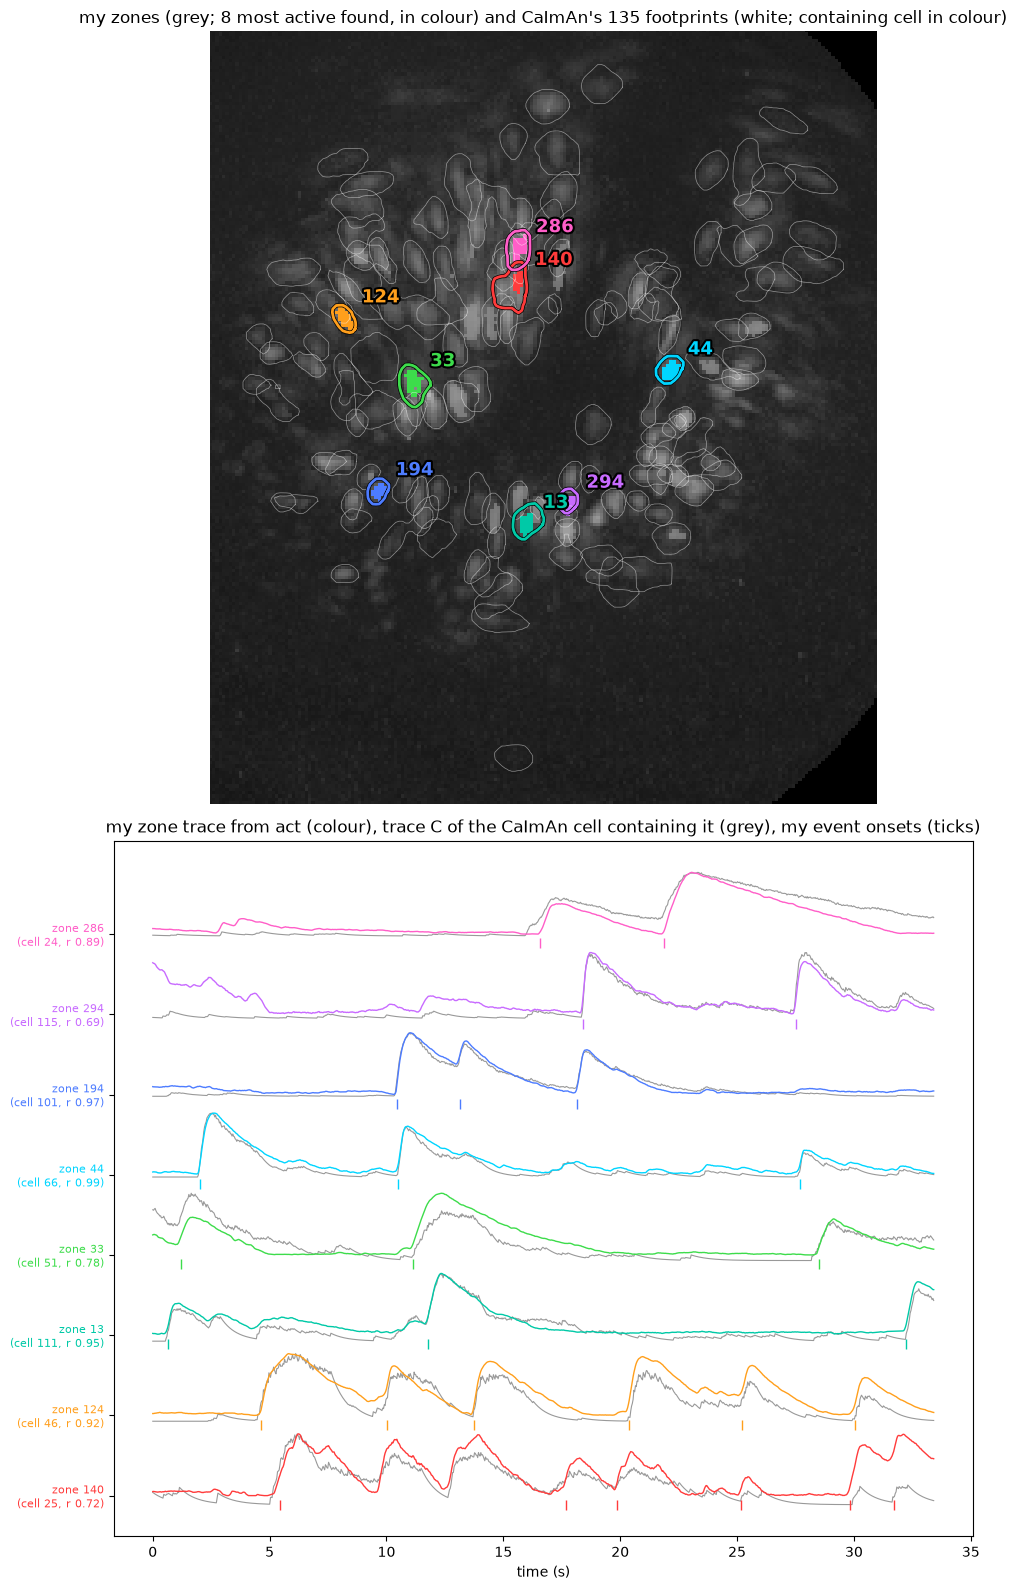

In [34]:
# Zones inside a single CaImAn cell: my trace (mean of act over the zone) vs the trace C of the cell containing it.
# Top: the 8 most active of these zones (filled, one colour each) and the CaImAn cell containing each (same colour);
# my other zones in grey, all CaImAn contours in white. Bottom: the traces, same colours.
C = cnm.estimates.C[:, :T]
cell = inside['cell']                                      # CaImAn cell containing each zone, -1 = none
found = np.flatnonzero(cell >= 0)
r = np.full(len(ids), np.nan)
r[found] = [np.corrcoef(traces[:, z], C[cell[z]])[0, 1] for z in found]
print(f"{len(found)} zones inside a single CaImAn cell: trace correlation median {np.nanmedian(r):.2f} "
      f"(range {np.nanmin(r):.2f} to {np.nanmax(r):.2f})")
top = found[np.argsort(-n_events[ids[found] - 1])[:8]]    # the 8 most active of them
col = ['#ff3b3b', '#ff9f1c', '#00c9a7', '#3ddc4b', '#00d5ff', '#4d7cff', '#c86bff', '#ff5ec8'][:len(top)]   # bright, no greys
import matplotlib.patheffects as pe
halo = [pe.withStroke(linewidth=3, foreground='black')]   # black outline so labels read on any background

fig, (ax, bx) = plt.subplots(2, 1, figsize=(10, 16), height_ratios=[1, 0.9])
ax.imshow(act.max(0) ** .5, cmap='Greys_r', vmin=0, vmax=(act.max(0) ** .5).max() / 0.6)   # dimmed, so the colours stand out
ax.imshow(np.ma.masked_equal(zmap > 0, 0), cmap='Greys', vmin=0, vmax=2, alpha=0.6, interpolation='nearest')
for c in conts:
    ax.plot(*c['coordinates'].T, color='w', lw=0.5, alpha=0.5)
for i, z in enumerate(top):
    ax.imshow(np.ma.masked_equal(zmap == ids[z], 0), cmap=plt.matplotlib.colors.ListedColormap([col[i]]),
              interpolation='nearest')
    ax.plot(*conts[cell[z]]['coordinates'].T, color=col[i], lw=2, path_effects=halo)
    y, x = ndimage.center_of_mass(zmap == ids[z])
    ax.text(x + 5, y - 5, str(ids[z]), color=col[i], fontsize=13, fontweight='bold', path_effects=halo)
allc = np.vstack([c['coordinates'] for c in conts]); allc = allc[np.isfinite(allc).all(1)]
(x0, y0), (x1, y1) = allc.min(0) - 10, allc.max(0) + 10          # crop to where the cells are
ax.set_xlim(x0, x1); ax.set_ylim(y1, y0); ax.set_axis_off()
ax.set_title(f"my zones (grey; 8 most active found, in colour) and CaImAn's {len(conts)} footprints (white; containing cell in colour)")

t = np.arange(T) / 29.78
for i, z in enumerate(top):
    on = t_first[ev_zone == ids[z] - 1] + 1                  # rise[j] is the step j -> j+1
    bx.plot(t, C[cell[z]] / C[cell[z]].max() + 1.3 * i, color='0.6', lw=0.8)
    bx.plot(t, traces[:, z] / traces[:, z].max() + 1.3 * i, color=col[i], lw=1)
    bx.plot(t[on], np.full(len(on), 1.3 * i - 0.15), '|', color=col[i], ms=7)
bx.set_yticks(1.3 * np.arange(len(top)), [f"zone {ids[z]}\n(cell {cell[z]}, r {r[z]:.2f})" for z in top], fontsize=8)
for lab, c in zip(bx.get_yticklabels(), col):
    lab.set_color(c)
bx.set_xlabel("time (s)")
bx.set_title("my zone trace from act (colour), trace C of the CaImAn cell containing it (grey), my event onsets (ticks)")
fig.tight_layout()

There are some differences, but agreement is pretty good there and, without surprise, the stronger the overlap in terms of detected zone on my detector versus detected cells via CNMF-E, the better the match. Zone 44 has a footprint matching a contour closely, and the curves almost overlap, while zone 140 is a small part of the area inside the contour. Demixing is also a factor there: CNMF-E can separate overlapping cells in a way my pixel-wise pipeline structurally cannot.

## Whole session, streamed

The same chain over the 9 files of the session (8935 frames, 5 min), chunk by chunk, so memory stays bounded whatever the session length. The temporal filters see enough frames of the neighbouring chunks that the result doesn't depend on where the files were cut. `streaming.py` was written with an AI assistant (Claude Code) at my request, from the chain above. Results are memory-mapped `.npy` files in `out/session`; if they already exist they are loaded, not recomputed (~4 min).

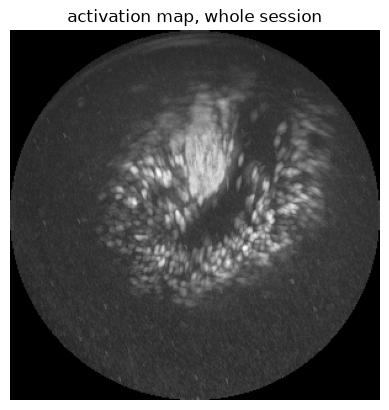

In [35]:
import streaming, fullsession
if not Path("out/session/act.npy").exists():
    streaming.run_session(files, "out/session")
act_s  = np.load("out/session/act.npy",  mmap_mode="r")   # (8935, 300, 300), no RAM cost until you slice
rise_s = np.load("out/session/rise.npy", mmap_mode="r")
peak_s = fullsession.peak_map(act_s)
plt.imshow(peak_s ** .5, cmap="Greys_r"); plt.title("activation map, whole session"); plt.axis("off");

<a id="traces-session"></a>
## Full session, compared with the authors' published extraction

My streamed results over the whole session (5 min): the activation map, zones built from the rise events, and their traces (mean of `act` over each zone). The reference is the authors' CNMF-E extraction stored in the session NWB: accepted components only, footprints downsampled to my 300×300 grid, traces aligned by frame index (row k of their C = raw frame k).

authors' extraction: 222 accepted cells; grid offset to my map: dy=0, dx=0 px


4508 rise events -> 166 zones seen at least 2 times, >= 9 px (median area 19 px)


space, zones >= 80% inside a single authors' cell (chance: zones rotated and moved at random, weighted by the density of authors' cells, Gaussian sigma 8 px = 1 cell diameter):
  inside one cell:           74/166 zones (45%, chance 23%)
  straddling or outside:     92/166 zones (55%)
  authors' cells with no zone: 148/222 (67%); with one: 74/222 (33%, chance 15%)


  of the 92 zones not inside an accepted cell, 29 are >= 80% inside a single component the authors rejected (157 rejected components)
74 zones inside a single authors' cell: trace correlation median 0.91 (range 0.63 to 0.98)


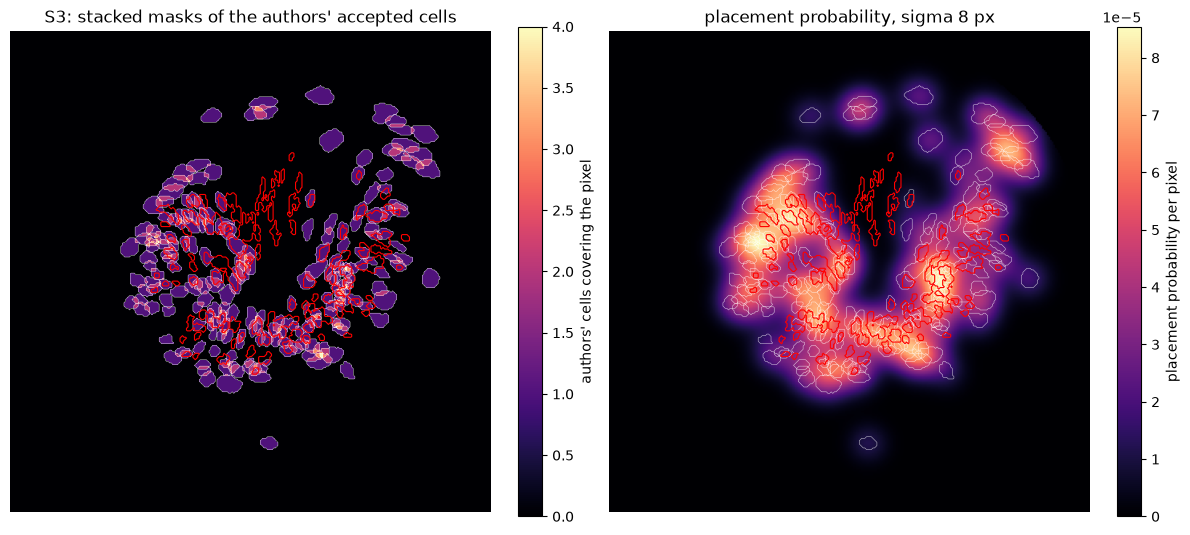

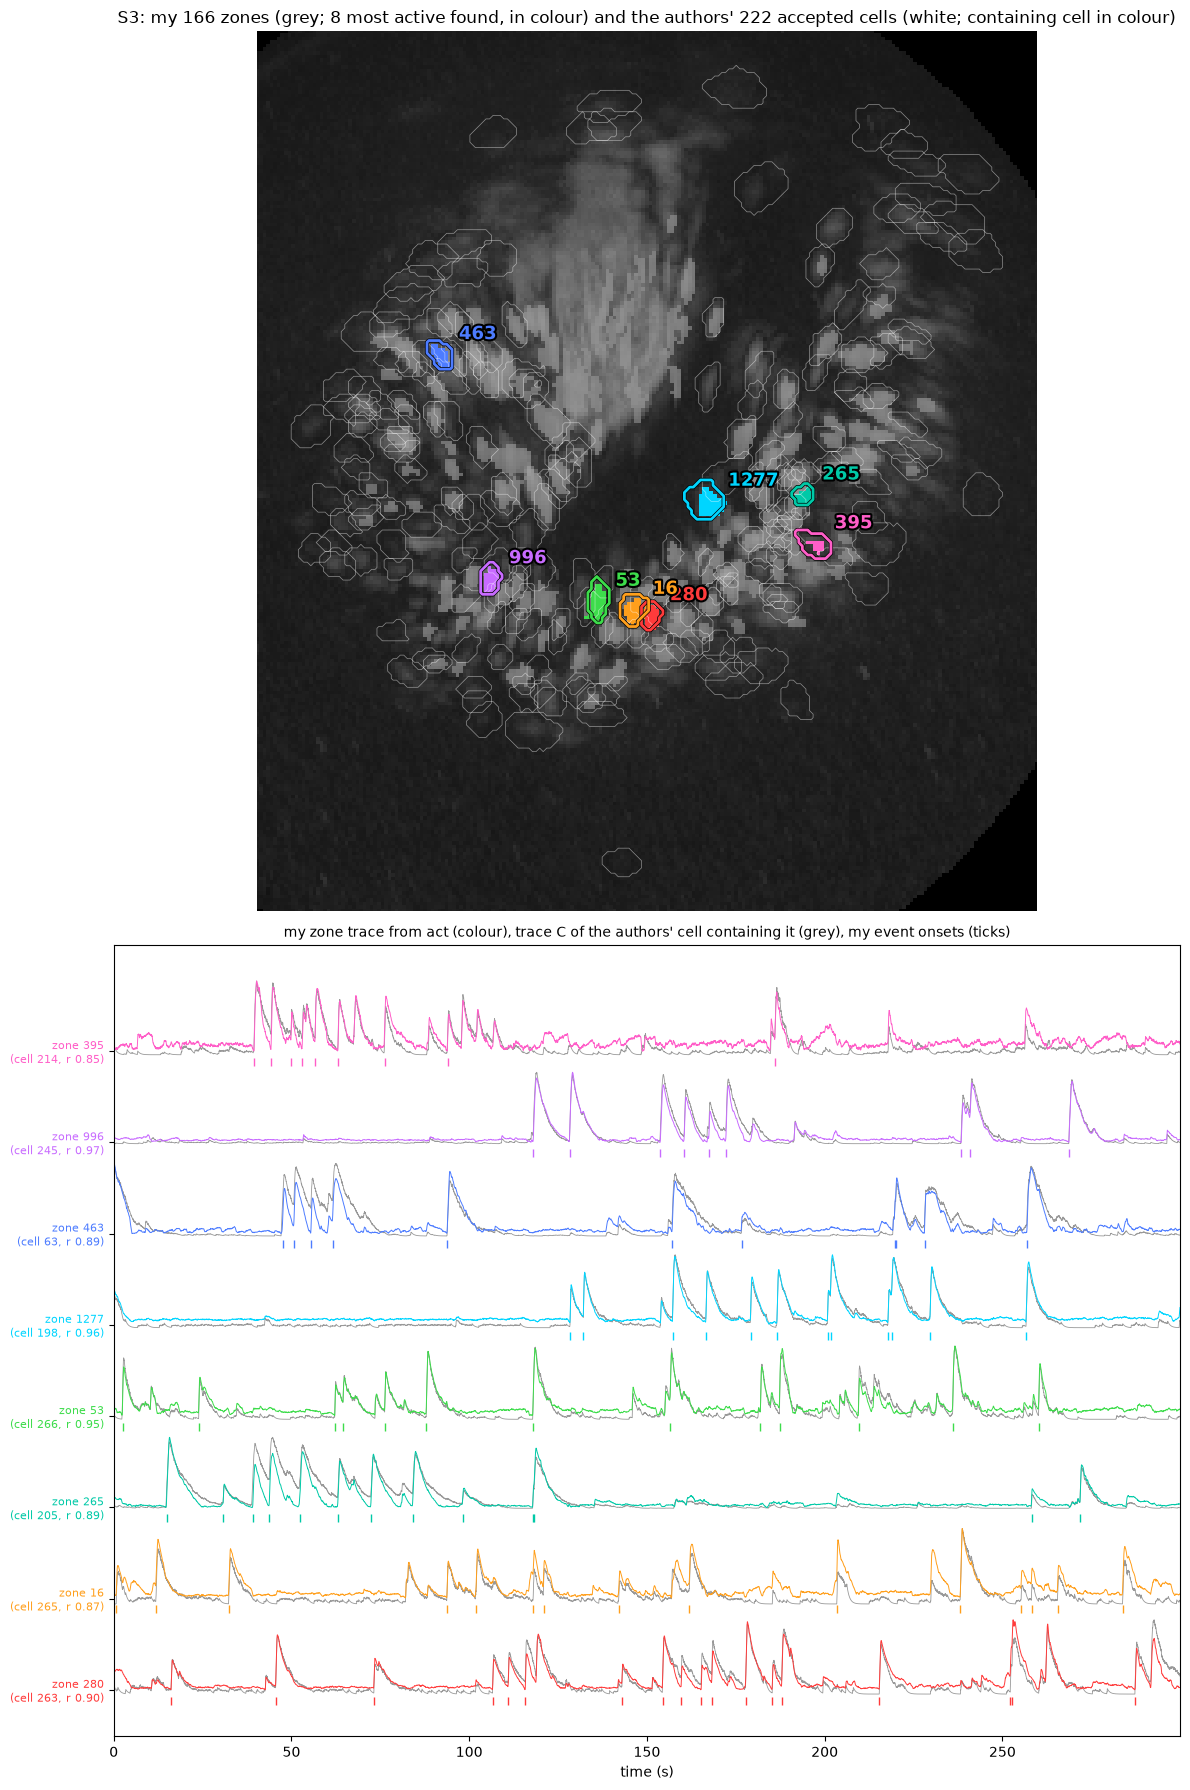

In [36]:
import fullsession
res = fullsession.compare_with_authors("out/session", "data/sub-F06/sub-F06_ses-CPFE-F06-S3_behavior+image+ophys.nwb", title="S3: ")

In [37]:
# My detector vs chance on the whole session, against the authors' accepted cells (same test as for the chunk)
res['table']

,my pipeline,chance
zones >= 80% inside a single authors' cell,74/166 (45%),37.8/166 (23%)
zones straddling two cells or outside,92/166 (55%),128.2/166 (77%)
authors' cells with one of my zones inside,74/222 (33%),33.3/222 (15%)
authors' cells with none of my zones,148/222 (67%),188.7/222 (85%)


The full session corroborates the conclusions from the first chunk. For zones 395, 996, 463 or 1277, in the calm regions, my trace rides slightly above the CaImAn-recovered ones. My own background subtraction relies on an opening of a noisy signal. This leaves a positive offset roughly equal to the local noise level, while CaImAn's trace is denoised and its baseline sits at zero. The authors' curation also matters here: they kept 222 of their 379 CNMF-E components using a classifier score (`ml_keep_probability` ≥ 0.72), and 29 of my 92 zones that miss an accepted cell sit at least 80% inside a single component it rejected. Deciding which components are real cells is outside what I know so far, so I can't tell yet whether these are false detections on my side or cells the classifier dropped.

As stated above, I don't claim this detector as being anything novel, it may be useful, at the margin as a fast and rough quality control display, but building it has helped me better understand the specific challenges of calcium imaging data processing, from the necessity of properly modelling the background, and of building a reliable noise model, to the nature of the measurement itself, and the challenges of recovering individual signals from overlapping cells in a dataset. On the practical side, seeing my machine eat tens of gigabytes of memory on CaImAn calls or while running my own pipeline prototype also drove home how much memory efficiency matters (hence the fact chunks are streamed one by one and not all loaded together for the full session run).